# Modeling Human Activity States with a Hidden Markov Model

**Author:** Tedla Tesfaye Godebo · ALU, Formative 2 (individual)

This notebook takes accelerometer and gyroscope recordings from my phone and:

1. loads and cleans them,
2. puts them on a common 100 Hz time grid,
3. cuts them into fixed windows and extracts time- and frequency-domain features,
4. trains a Gaussian Hidden Markov Model **implemented from scratch in numpy** (forward–backward, Baum–Welch with a log-likelihood convergence check, and Viterbi),
5. evaluates it on held-out recordings and on the unseen test files.

Every figure used in the report is saved to `figures/`.

## 0. Setup

In [ ]:
import glob, os, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
pd.set_option('display.precision', 3)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})

DATA_DIR = 'data'
FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

ACTIVITIES = ['still', 'standing', 'walking', 'jumping']
COLORS = {'still': '#7f7f7f', 'standing': '#1f77b4', 'walking': '#2ca02c', 'jumping': '#d62728'}

FS = 100
TRIM_S = 1.0
MAX_LEN_S = 10.0
WIN_S = 2.0
HOP_S = 1.0

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name))

## 1. Data collection and loading

**Recording setup.** All data were recorded with one phone (iPhone 13 Pro Max, iOS) in the Sensor Logger app (v1.68). The accelerometer and gyroscope were both set to **100 Hz**. The phone was held flat, screen up, at waist level. For *still*, it lay flat on a surface. Each activity has 13 recordings of about 10–12 s, made over three days (23, 25 and 26 October 2026) in different places. That gives **52 training files**.

**Files.** `data/train/<activity>/<activity>_NN.csv` holds one merged file per recording, with these columns:
`timestamp_ns, seconds_elapsed, acc_x, acc_y, acc_z` (m/s², gravity removed by iOS), `gyro_x, gyro_y, gyro_z` (rad/s), and `activity`.
The untouched app exports are in `data/raw/`.

In [2]:
index = pd.read_csv(os.path.join(DATA_DIR, 'recordings_index.csv'))
print(index.groupby('activity').agg(files=('recording', 'count'),
                                    raw_seconds=('duration_s', 'sum'),
                                    sampling_rate_hz=('sampling_rate_hz', 'median'),
                                    max_gap_ms=('max_gap_ms', 'max')).loc[ACTIVITIES])
print('\nTotal files:', len(index), '| devices:', list(index.device.unique()))

          files  raw_seconds  sampling_rate_hz  max_gap_ms
activity                                                  
still        13       141.74              99.7        10.0
standing     13       137.07              99.7        12.0
walking      13       138.29              99.7        10.0
jumping      13       136.36              99.7        10.0

Total files: 52 | devices: ['iPhone 13 Pro Max']


### 1.1 Sampling-rate harmonisation

Only one phone was used, so there is no mismatch between devices. Real sensor timestamps still jitter, though. The median interval is 10.03 ms (99.7 Hz), and the largest single gap is 12 ms. The FFT features assume evenly spaced samples. So every recording is **linearly interpolated onto an exact 100 Hz grid** built from its own timestamps. This step would also bring a second phone recording at 50 Hz or 200 Hz onto the same grid, so the window length in samples always means the same length in seconds.

In [3]:
SENSOR_COLS = ['acc_x', 'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z']

def resample_uniform(df, fs=FS):
    # Interpolate all sensor channels onto a uniform fs-Hz grid using the real timestamps.
    t = (df['timestamp_ns'].values - df['timestamp_ns'].values[0]) / 1e9
    grid = np.arange(0, t[-1], 1 / fs)
    out = pd.DataFrame({'t': grid})
    for c in SENSOR_COLS:
        out[c] = np.interp(grid, t, df[c].values)
    out['t_rec'] = grid + df['seconds_elapsed'].values[0]   # time since recording start (for test labels)
    return out

def clean(df, trim=TRIM_S, max_len=MAX_LEN_S):
    # Drop the first/last `trim` seconds (screen-tap artefacts), then cap the length at max_len.
    keep = (df['t'] >= trim) & (df['t'] <= df['t'].iloc[-1] - trim)
    df = df[keep]
    if max_len is not None:
        df = df[df['t'] < df['t'].iloc[0] + max_len]
    return df.reset_index(drop=True)

def load_train():
    recs = []
    for act in ACTIVITIES:
        for path in sorted(glob.glob(os.path.join(DATA_DIR, 'train', act, '*.csv'))):
            raw = pd.read_csv(path)
            recs.append({'rec': os.path.basename(path)[:-4], 'activity': act,
                         'raw': raw, 'data': clean(resample_uniform(raw))})
    return recs

train_recs = load_train()
lengths = pd.DataFrame([{'activity': r['activity'], 'clean_s': len(r['data']) / FS} for r in train_recs])
summary = lengths.groupby('activity')['clean_s'].agg(['count', 'min', 'max', 'sum']).loc[ACTIVITIES]
summary['sum_min:s'] = summary['sum'].apply(lambda s: f'{int(s // 60)}:{int(s % 60):02d}')
print(summary)

          count   min    max     sum sum_min:s
activity                                      
still        13  8.08  10.00  115.66      1:55
standing     13  7.99   9.15  111.11      1:51
walking      13  7.93   9.06  112.32      1:52
jumping      13  7.84   9.54  110.39      1:50


### 1.2 Visualising sample data

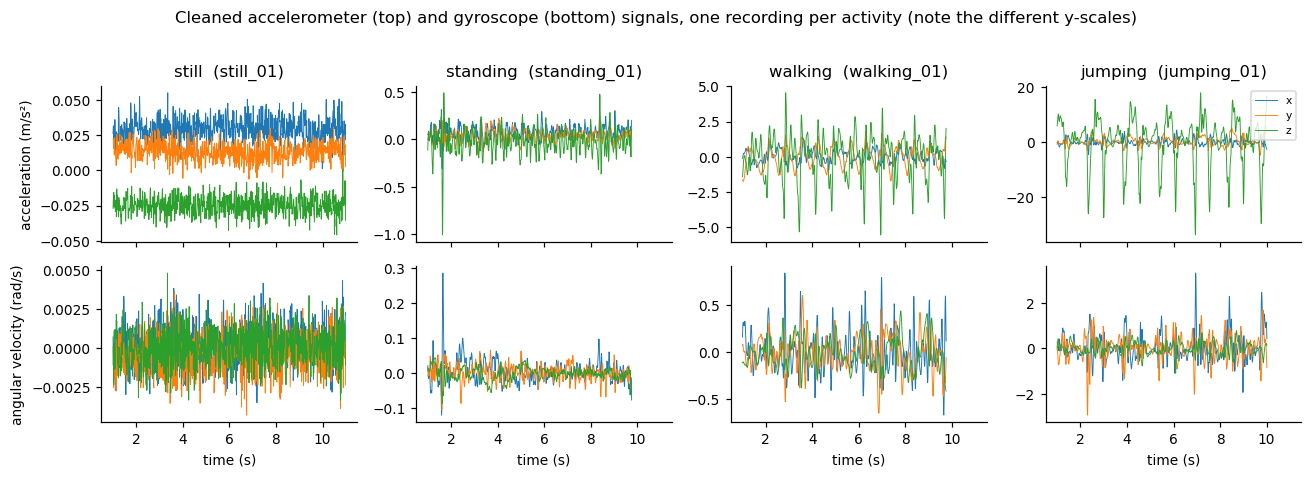

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(12, 4.2), sharex=True)
for j, act in enumerate(ACTIVITIES):
    r = next(r for r in train_recs if r['activity'] == act)
    d = r['data']
    for c, col in zip(['x', 'y', 'z'], ['#1f77b4', '#ff7f0e', '#2ca02c']):
        axes[0, j].plot(d['t'], d[f'acc_{c}'], lw=.6, color=col, label=c)
        axes[1, j].plot(d['t'], d[f'gyro_{c}'], lw=.6, color=col, label=c)
    axes[0, j].set_title(f"{act}  ({r['rec']})")
    axes[1, j].set_xlabel('time (s)')
axes[0, 0].set_ylabel('acceleration (m/s²)'); axes[1, 0].set_ylabel('angular velocity (rad/s)')
axes[0, 3].legend(loc='upper right', fontsize=7)
fig.suptitle('Cleaned accelerometer (top) and gyroscope (bottom) signals, one recording per activity '
             '(note the different y-scales)', y=1.02)
plt.tight_layout(); savefig('fig01_raw_signals.png'); plt.show()

## 2. Windowing and feature extraction

**Window size from the sampling rate.** At 100 Hz, a **2 s window is 200 samples**, and windows advance by 1 s (100 samples, 50 % overlap).
* The slowest repeating motion is walking, at about 1.5–2 steps/s. 2 s covers at least 3 full step or jump cycles, so the spectrum shows a clear peak instead of a fragment of one cycle.
* The FFT frequency resolution is fs/N = 100/200 = **0.5 Hz**. That is fine enough to separate walking (about 1.5–2 Hz cadence) from jumping (about 2 jumps/s, with stronger harmonics).
* 1 s steps give 7–9 observations per training file and one HMM time step per second. That is short enough to follow activity changes in the test recordings.
* Longer windows (e.g. 4 s) would blur transitions and leave only 3–5 windows per file. Shorter windows (e.g. 0.5 s, 50 samples) would cut walking cycles and give 2 Hz frequency resolution.

**Features (10 per window).** These come from the acceleration magnitude |a| = √(ax²+ay²+az²) and the gyroscope magnitude |ω|. Using magnitudes makes the features independent of how the phone is rotated in the hand.

| # | Feature | Domain | Why it separates the activities |
|---|---|---|---|
| 1 | `acc_mag_mean` | time | Average movement intensity. Near 0 when still, small for standing (hand tremor), large for walking, very large for jumping. |
| 2 | `acc_mag_std` | time | How much the intensity varies. Periodic impacts (steps, landings) give high variance. |
| 3 | `acc_sma` | time | Signal magnitude area, mean(|ax|+|ay|+|az|). A standard energy-expenditure proxy in activity recognition. |
| 4 | `acc_p2p` | time | Peak-to-peak range. Captures the very sharp landing spikes (up to 40 m/s²) that only jumping produces. |
| 5 | `gyro_mag_mean` | time | Average rotation rate. Separates "phone on a table" (no rotation at all) from "phone in a hand" (small rotations) better than acceleration does. |
| 6 | `gyro_mag_std` | time | Variability of the rotation. Swinging and bouncing during walking and jumping. |
| 7 | `acc_dom_freq` | frequency (FFT) | Frequency of the largest FFT peak, 0.5–20 Hz. The movement rhythm: walking and jumping have fixed cadences, while still and standing only have broadband noise. |
| 8 | `acc_spec_energy` | frequency (FFT) | Total spectral power, Σ|X(f)|²/N. Movement energy in the frequency domain. Differs by about 10⁶ between still and jumping. |
| 9 | `acc_band_ratio` | frequency (FFT) | Share of power in the 0.5–3 Hz human-locomotion band. High for walking, lower for jumping (energy moves into harmonics from the sharp impacts), low for noise. |
| 10 | `acc_spec_entropy` | frequency (FFT) | Normalised spectral entropy. Low when there is a clear rhythm (walking, jumping), close to 1 for white sensor noise (still, standing). |

The FFT uses a Hann window on the mean-removed magnitude, to reduce spectral leakage at the window edges.

In [5]:
WIN = int(WIN_S * FS)   # 200 samples
HOP = int(HOP_S * FS)   # 100 samples
FEATURES = ['acc_mag_mean', 'acc_mag_std', 'acc_sma', 'acc_p2p', 'gyro_mag_mean', 'gyro_mag_std',
            'acc_dom_freq', 'acc_spec_energy', 'acc_band_ratio', 'acc_spec_entropy']
LOG_FEATURES = ['acc_mag_mean', 'acc_mag_std', 'acc_sma', 'acc_p2p', 'gyro_mag_mean', 'gyro_mag_std',
                'acc_spec_energy']   # strictly positive, span several orders of magnitude

def sliding_windows(df, win=WIN, hop=HOP):
    # Yield (start_index, window_dataframe) for every full window.
    for s in range(0, len(df) - win + 1, hop):
        yield s, df.iloc[s:s + win]

def extract_features(w, fs=FS):
    # Compute the 10 time- and frequency-domain features for one window.
    acc = w[['acc_x', 'acc_y', 'acc_z']].values
    gyr = w[['gyro_x', 'gyro_y', 'gyro_z']].values
    a = np.linalg.norm(acc, axis=1)
    g = np.linalg.norm(gyr, axis=1)

    # frequency domain: FFT of the mean-removed, Hann-tapered acceleration magnitude
    x = (a - a.mean()) * np.hanning(len(a))
    power = np.abs(np.fft.rfft(x)) ** 2
    freqs = np.fft.rfftfreq(len(a), 1 / fs)
    band = (freqs >= 0.5) & (freqs <= 20)
    p_band = power[band]
    p_norm = p_band / p_band.sum()

    return {
        'acc_mag_mean': a.mean(),
        'acc_mag_std': a.std(),
        'acc_sma': np.abs(acc).sum(axis=1).mean(),
        'acc_p2p': a.max() - a.min(),
        'gyro_mag_mean': g.mean(),
        'gyro_mag_std': g.std(),
        'acc_dom_freq': freqs[band][p_band.argmax()],
        'acc_spec_energy': p_band.sum() / len(a),
        'acc_band_ratio': power[(freqs >= 0.5) & (freqs <= 3)].sum() / p_band.sum(),
        'acc_spec_entropy': -(p_norm * np.log2(p_norm + 1e-12)).sum() / np.log2(len(p_norm)),
    }

def featurize(recs):
    rows = []
    for r in recs:
        for i, (s, w) in enumerate(sliding_windows(r['data'])):
            f = extract_features(w)
            f.update(rec=r['rec'], activity=r['activity'], win=i)
            rows.append(f)
    return pd.DataFrame(rows)

feat_train = featurize(train_recs)
feat_train['session'] = feat_train['rec'].str[-2:].astype(int).map(lambda n: 'A (23 Oct)' if n <= 4 else 'B (25–26 Oct)')
print('Windows per activity:\n', feat_train.groupby('activity').size().loc[ACTIVITIES])
print('\nFeature means per activity (raw units):')
feat_train.groupby('activity')[FEATURES].mean().loc[ACTIVITIES].T

Windows per activity:
 activity
still       96
standing    91
walking     91
jumping     91
dtype: int64

Feature means per activity (raw units):


activity,still,standing,walking,jumping
acc_mag_mean,2.513e-02,0.126,2.203,9.612
acc_mag_std,6.252e-03,0.069,1.107,5.783
acc_sma,3.667e-02,0.186,2.985,11.767
acc_p2p,3.555e-02,0.371,5.633,28.341
gyro_mag_mean,1.899e-03,0.028,0.347,0.908
gyro_mag_std,8.980e-04,0.015,0.180,0.487
acc_dom_freq,9.151e+00,3.824,3.154,3.835
acc_spec_energy,8.627e-04,0.171,46.735,1252.382
acc_band_ratio,1.611e-01,0.312,0.387,0.208
acc_spec_entropy,8.900e-01,0.849,0.793,0.723


### 2.1 Example spectra

The plot below shows the FFT of one window per activity. Walking and jumping have clear peaks at their cadence and its harmonics. Still and standing show flat, low-power noise. That is why dominant frequency, band ratio and spectral entropy add information that the time-domain features don't capture.

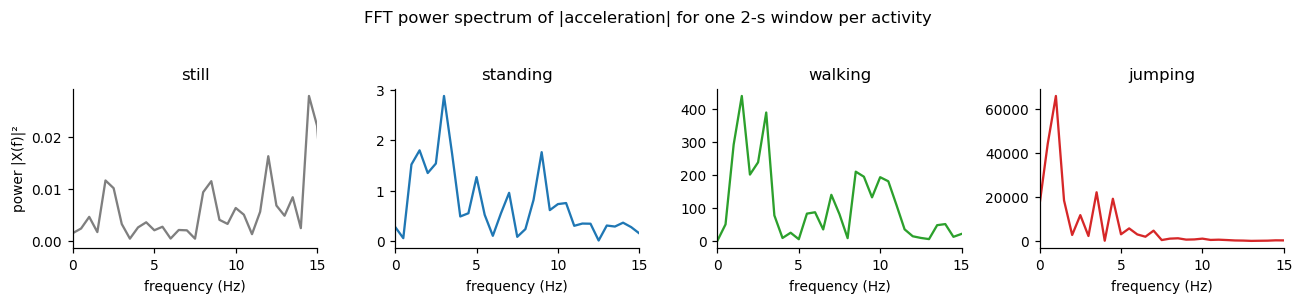

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(12, 2.6))
for ax, act in zip(axes, ACTIVITIES):
    r = next(r for r in train_recs if r['activity'] == act)
    w = r['data'].iloc[300:300 + WIN]
    a = np.linalg.norm(w[['acc_x', 'acc_y', 'acc_z']].values, axis=1)
    x = (a - a.mean()) * np.hanning(len(a))
    P = np.abs(np.fft.rfft(x)) ** 2; f = np.fft.rfftfreq(len(a), 1 / FS)
    ax.plot(f, P, color=COLORS[act]); ax.set_xlim(0, 15)
    ax.set_title(act); ax.set_xlabel('frequency (Hz)')
axes[0].set_ylabel('power |X(f)|²')
fig.suptitle('FFT power spectrum of |acceleration| for one 2-s window per activity', y=1.04)
plt.tight_layout(); savefig('fig02_spectra.png'); plt.show()

### 2.2 Normalisation

The features have very different units and ranges: m/s², rad/s, Hz, unitless ratios, and spectral energy spanning six orders of magnitude. Two steps are applied:

1. **log₁₀ transform** of the seven strictly positive magnitude and energy features. Their spread is multiplicative (still is about 10× quieter than standing, which is about 10× quieter than walking). The log turns that into evenly spaced, roughly Gaussian clusters, which matches the HMM's Gaussian emission assumption.
2. **Z-score standardisation**, z = (x − μ)/σ, using μ and σ computed **on the training windows only** and reused unchanged for validation and test data (no information leaks from the test set). Z-scoring puts every feature on the same scale. Otherwise the large-range features would dominate the Gaussian log-likelihood and the variance floor would mean different things for different features. Min–max scaling was rejected because one extreme jump spike would squash all the other values.

Training features after normalisation: mean ≈ [ 0. -0.  0.  0.  0.  0. -0.  0.  0. -0.] 
 std ≈ [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


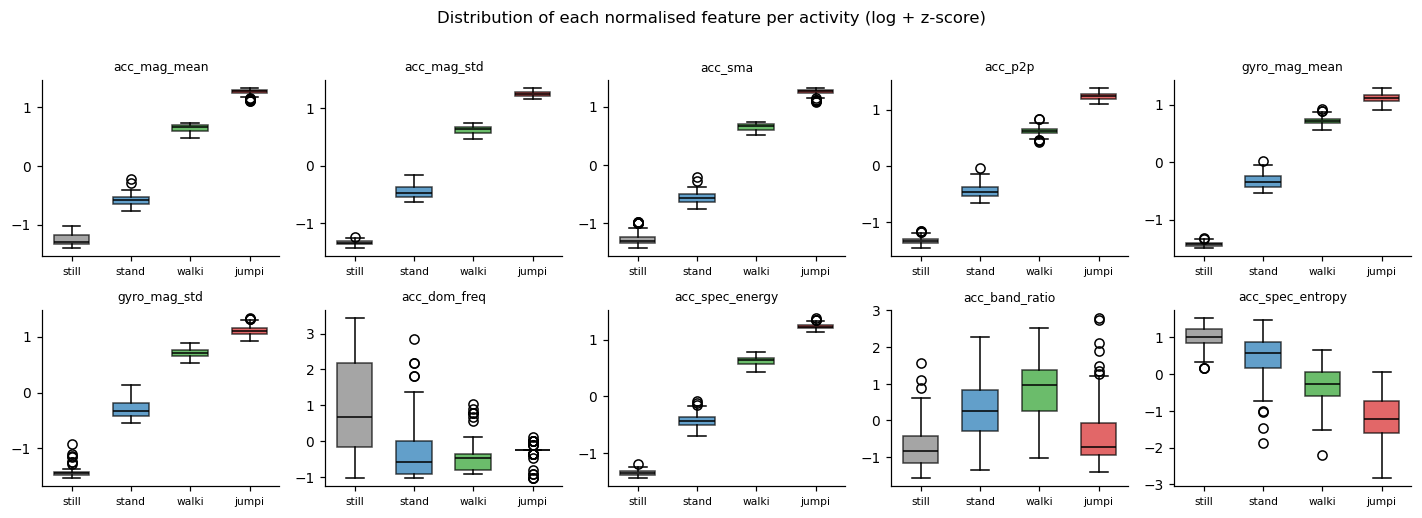

In [7]:
class FeatureScaler:
    # log10 on positive-magnitude features, then z-score with statistics learned from training data.
    def fit(self, df):
        L = self._log(df)
        self.mean_, self.std_ = L.mean(), L.std()
        return self
    def transform(self, df):
        return ((self._log(df) - self.mean_) / self.std_).values
    @staticmethod
    def _log(df):
        L = df[FEATURES].copy()
        for c in LOG_FEATURES:
            L[c] = np.log10(L[c] + 1e-6)
        return L

scaler = FeatureScaler().fit(feat_train)
Z_train = scaler.transform(feat_train)
print('Training features after normalisation: mean ≈', Z_train.mean(0).round(2), '\n std ≈', Z_train.std(0).round(2))

fig, axes = plt.subplots(2, 5, figsize=(13, 4.6))
for k, (ax, name) in enumerate(zip(axes.ravel(), FEATURES)):
    data = [Z_train[feat_train['activity'].values == a, k] for a in ACTIVITIES]
    bp = ax.boxplot(data, patch_artist=True, widths=.6, medianprops=dict(color='k'))
    for patch, a in zip(bp['boxes'], ACTIVITIES):
        patch.set_facecolor(COLORS[a]); patch.set_alpha(.7)
    ax.set_xticks(range(1, 5)); ax.set_xticklabels([a[:5] for a in ACTIVITIES], fontsize=7)
    ax.set_title(name, fontsize=8)
fig.suptitle('Distribution of each normalised feature per activity (log + z-score)', y=1.01)
plt.tight_layout(); savefig('fig03_features.png'); plt.show()

## 3. HMM components

| Element | In this model |
|---|---|
| **Hidden states Z** | 4 activities: still, standing, walking, jumping (one Gaussian state each) |
| **Observations X** | One 10-dimensional normalised feature vector per 2 s window (1 s step) |
| **Transition matrix A** (4×4) | P(z_t = j \| z_{t−1} = i). How likely the activity is to continue or change from one second to the next |
| **Emission model B** | P(x_t \| z_t = k) = 𝒩(x_t; μ_k, diag σ²_k), a Gaussian with diagonal covariance per state |
| **Initial distribution π** | P(z_1 = k), the probability that a sequence starts in each activity |

**Why diagonal Gaussians?** There are about 90 training windows per state. A full covariance needs 55 parameters per state for 10 features, against 10 for a diagonal one. That is too many to estimate reliably from this data. The diagonal model is less prone to overfitting, and the log + z-score step already makes each feature close to Gaussian.

### Algorithm choice

* **Baum–Welch (EM with forward–backward)** *learns* π, A, μ and σ² by maximising the likelihood of the training sequences. It is the right algorithm here because the hidden states are never observed directly, only the sensor features. A log-likelihood convergence test (|ΔLL| < ε) decides when to stop.
* **Viterbi** *decodes* the single most likely activity sequence for a new recording. That sequence produces the per-window predictions behind the confusion matrix, sensitivity, specificity and accuracy. Viterbi's main benefit for these metrics is that the transition matrix punishes implausible flips over a single window. Isolated misclassifications (e.g. one noisy walking window labelled *jumping*) get smoothed away. That raises **specificity** (fewer false positives) and overall **accuracy** compared with classifying each window independently.
* The **forward algorithm** also gives P(X | model), which is the likelihood tracked for convergence.

### Implementation notes
* Everything runs in **log space**, using a custom `logsumexp`, so long sequences cannot underflow.
* Baum–Welch takes **multiple sequences** (one per recording) and sums the expected counts across them.
* A **variance floor** (10⁻³) stops a state's Gaussian from collapsing onto a few identical windows. The *still* windows are nearly constant, so this matters.
* **Transition prior.** Each training file contains a single activity, so the data only ever show "stay in the same state". Plain maximum likelihood would make A diagonal, and Viterbi could then never switch activity in a test recording. So I add **Dirichlet pseudo-counts** to the transition update (MAP-EM). They encode common-sense behaviour: you move between neighbouring activities (still ↔ standing ↔ walking ↔ jumping) more often than between distant ones (still → jumping). The self-transition probabilities are still learned from the data.

In [8]:
def logsumexp(a, axis=None, keepdims=False):
    # Numerically stable log(sum(exp(a))) along an axis.
    m = np.max(a, axis=axis, keepdims=True)
    m = np.where(np.isfinite(m), m, 0.0)
    out = np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)) + m
    return out if keepdims else np.squeeze(out, axis=axis)


class GaussianHMM:
    # Hidden Markov Model with diagonal-covariance Gaussian emissions, implemented from scratch.
    #
    # Parameters
    # ----------
    # n_states    : number of hidden states K
    # tol         : stop Baum–Welch when the training objective improves by less than tol
    # max_iter    : safety cap on iterations (not the stopping rule)
    # var_floor   : lower bound on every emission variance
    # trans_prior : (K, K) Dirichlet pseudo-counts added to expected transition counts (MAP-EM)

    def __init__(self, n_states, tol=1e-4, max_iter=500, var_floor=1e-3, trans_prior=None):
        self.K, self.tol, self.max_iter, self.var_floor = n_states, tol, max_iter, var_floor
        self.trans_prior = np.zeros((n_states, n_states)) if trans_prior is None else np.asarray(trans_prior, float)

    # ---------- emission model ----------
    def log_emission(self, X):
        # log N(x_t | mu_k, diag var_k) for every t and k -> (T, K)
        diff2 = (X[:, None, :] - self.means[None]) ** 2
        return -0.5 * (np.log(2 * np.pi * self.vars).sum(-1)[None] + (diff2 / self.vars[None]).sum(-1))

    # ---------- forward–backward ----------
    def _forward(self, logB):
        T = len(logB); log_alpha = np.empty((T, self.K)); logA = np.log(self.A)
        log_alpha[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            log_alpha[t] = logsumexp(log_alpha[t - 1][:, None] + logA, axis=0) + logB[t]
        return log_alpha

    def _backward(self, logB):
        T = len(logB); log_beta = np.zeros((T, self.K)); logA = np.log(self.A)
        for t in range(T - 2, -1, -1):
            log_beta[t] = logsumexp(logA + (logB[t + 1] + log_beta[t + 1])[None], axis=1)
        return log_beta

    def log_likelihood(self, X):
        # log P(X | model) via the forward algorithm.
        return logsumexp(self._forward(self.log_emission(X))[-1])

    def posteriors(self, X):
        # gamma_t(k) = P(z_t = k | X) (posterior state probabilities).
        logB = self.log_emission(X)
        la, lb = self._forward(logB), self._backward(logB)
        return np.exp(la + lb - logsumexp(la[-1]))

    # ---------- Viterbi ----------
    def viterbi(self, X):
        # Most likely hidden-state path and its log-probability.
        logB = self.log_emission(X); T = len(X); logA = np.log(self.A)
        delta = np.empty((T, self.K)); psi = np.zeros((T, self.K), dtype=int)
        delta[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            scores = delta[t - 1][:, None] + logA          # (from i, to j)
            psi[t] = scores.argmax(axis=0)
            delta[t] = scores.max(axis=0) + logB[t]
        path = np.empty(T, dtype=int); path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path, delta[-1].max()

    # ---------- Baum–Welch ----------
    def fit(self, sequences, pi, A, means, vars_):
        # Baum–Welch on a list of (T_i, D) observation sequences, starting from the given parameters.
        self.pi, self.A = np.array(pi, float), np.array(A, float)
        self.means, self.vars = np.array(means, float), np.array(vars_, float)
        X_all = np.vstack(sequences)
        self.history, self.converged = [], False

        for it in range(self.max_iter):
            # ----- E-step -----
            logA = np.log(self.A)
            gammas, xi_sum, gamma0, loglik = [], np.zeros((self.K, self.K)), np.zeros(self.K), 0.0
            for X in sequences:
                logB = self.log_emission(X)
                la, lb = self._forward(logB), self._backward(logB)
                ll = logsumexp(la[-1]); loglik += ll
                gamma = np.exp(la + lb - ll)
                gammas.append(gamma); gamma0 += gamma[0]
                # expected transitions: xi_t(i,j) = alpha_t(i) a_ij b_j(x_{t+1}) beta_{t+1}(j) / P(X)
                log_xi = la[:-1, :, None] + logA[None] + (logB[1:] + lb[1:])[:, None, :] - ll
                xi_sum += np.exp(log_xi).sum(axis=0)

            objective = loglik + (self.trans_prior * logA).sum()     # log-likelihood + log Dirichlet prior
            self.history.append({'iteration': it, 'log_likelihood': loglik, 'objective': objective})

            # ----- convergence check: |Δ objective| < tol -----
            if it > 0 and abs(objective - self.history[-2]['objective']) < self.tol:
                self.converged = True
                break

            # ----- M-step -----
            G = np.vstack(gammas); w = G.sum(axis=0)
            self.pi = (gamma0 + 1.0) / (gamma0 + 1.0).sum()                  # +1 Laplace smoothing
            counts = xi_sum + self.trans_prior
            self.A = counts / counts.sum(axis=1, keepdims=True)
            self.means = (G.T @ X_all) / w[:, None]
            self.vars = np.maximum((G.T @ X_all ** 2) / w[:, None] - self.means ** 2, self.var_floor)
        return self

### 3.1 Initialisation and transition prior

Training uses one observation sequence per recording, 52 sequences in total. Baum–Welch is started from the **per-activity mean and variance of the labelled training windows**, so state *k* begins as activity *k*. A starts at 0.94 on the diagonal. Baum–Welch then refines all the parameters freely.

The Dirichlet pseudo-counts for A (rows = from, columns = to) are:

| from \ to | still | standing | walking | jumping |
|---|---|---|---|---|
| still | – | 3 | 1 | 0.25 |
| standing | 3 | – | 3 | 1 |
| walking | 1 | 3 | – | 3 |
| jumping | 0.25 | 1 | 3 | – |

Each state has roughly 70 observed self-transitions in the training data. So these few pseudo-counts give off-diagonal probabilities of about 0.3–4 %. That allows a switch when the evidence is strong, without overriding the data.

In [9]:
TRANS_PRIOR = np.array([[0,    3, 1, 0.25],
                        [3,    0, 3, 1   ],
                        [1,    3, 0, 3   ],
                        [0.25, 1, 3, 0   ]])

def to_sequences(feat_df, Z):
    # Split the window matrix into one sequence per recording (keeps time order).
    seqs, labels, recs = [], [], []
    for rec, g in feat_df.groupby('rec', sort=False):
        idx = g.sort_values('win').index.values
        seqs.append(Z[idx]); labels.append(g.loc[idx, 'activity'].map(ACTIVITIES.index).values); recs.append(rec)
    return seqs, labels, recs

def init_from_labels(seqs, labels, K=4, stay=0.94):
    X, y = np.vstack(seqs), np.concatenate(labels)
    means = np.array([X[y == k].mean(0) for k in range(K)])
    vars_ = np.array([X[y == k].var(0) for k in range(K)]) + 1e-3
    A0 = np.full((K, K), (1 - stay) / (K - 1)); np.fill_diagonal(A0, stay)
    return np.full(K, 1 / K), A0, means, vars_

feat_train = feat_train.reset_index(drop=True)
train_seqs, train_labels, train_rec_ids = to_sequences(feat_train, Z_train)
print(f'{len(train_seqs)} training sequences, lengths {min(map(len, train_seqs))}–{max(map(len, train_seqs))} windows')

hmm = GaussianHMM(n_states=4, tol=1e-4, trans_prior=TRANS_PRIOR)
hmm.fit(train_seqs, *init_from_labels(train_seqs, train_labels))
h = pd.DataFrame(hmm.history)
print(f"Converged: {hmm.converged} after {len(h)} iterations "
      f"(|ΔLL| < {hmm.tol}); log-likelihood {h.log_likelihood.iloc[0]:.2f} -> {h.log_likelihood.iloc[-1]:.2f}")

52 training sequences, lengths 6–9 windows
Converged: True after 3 iterations (|ΔLL| < 0.0001); log-likelihood 1926.97 -> 1966.20


### 3.2 Does Baum–Welch find the activities without labels?

With label-based initialisation, Baum–Welch only needs a few iterations, because the starting point is already close to the optimum. As a stronger test of the implementation, I also run it **fully unsupervised**: 10 restarts, each starting from 4 random training windows as means, unit variances and a flat transition prior. Afterwards the states are matched to activities with the best of the 4! = 24 permutations. If the restart with the highest likelihood matches the labels, then the four activities really are the natural hidden states in the data.

In [10]:
def best_state_mapping(pred_states, true_labels, K=4):
    # Permutation state->activity that maximises agreement (brute force over K! permutations).
    best = max(itertools.permutations(range(K)), key=lambda p: (np.array(p)[pred_states] == true_labels).mean())
    return np.array(best)

y_train = np.concatenate(train_labels)
restarts = []
for seed in range(10):
    rng = np.random.default_rng(seed)
    X_all = np.vstack(train_seqs)
    m = GaussianHMM(4, tol=1e-4, trans_prior=np.full((4, 4), 0.5))
    A0 = np.full((4, 4), 0.1 / 3); np.fill_diagonal(A0, 0.9)
    m.fit(train_seqs, np.full(4, .25), A0, X_all[rng.choice(len(X_all), 4, replace=False)], np.ones((4, len(FEATURES))))
    states = np.concatenate([m.viterbi(X)[0] for X in train_seqs])
    mapping = best_state_mapping(states, y_train)
    restarts.append({'seed': seed, 'iterations': len(m.history), 'converged': m.converged,
                     'final_log_likelihood': m.history[-1]['log_likelihood'],
                     'accuracy_after_mapping': (mapping[states] == y_train).mean(), 'model': m})
restart_df = pd.DataFrame(restarts).drop(columns='model').sort_values('final_log_likelihood', ascending=False)
print(restart_df.to_string(index=False))
best = restart_df.iloc[0]
print(f"\nBest unsupervised restart (seed {int(best.seed)}): LL = {best.final_log_likelihood:.2f}, "
      f"accuracy after state mapping = {best.accuracy_after_mapping:.3f}")
print(f"Label-initialised model:                 LL = {hmm.history[-1]['log_likelihood']:.2f}")

 seed  iterations  converged  final_log_likelihood  accuracy_after_mapping
    9           6       True              1981.983                   1.000
    6           5       True              1981.983                   1.000
    8           5       True              1981.983                   1.000
    3          13       True               289.818                   0.659
    2          13       True               289.818                   0.659
    7           9       True              -104.848                   0.691
    5          30       True              -104.848                   0.691
    4          24       True              -104.848                   0.691
    0          25       True              -104.848                   0.691
    1          25       True              -104.848                   0.691

Best unsupervised restart (seed 9): LL = 1981.98, accuracy after state mapping = 1.000
Label-initialised model:                 LL = 1966.20


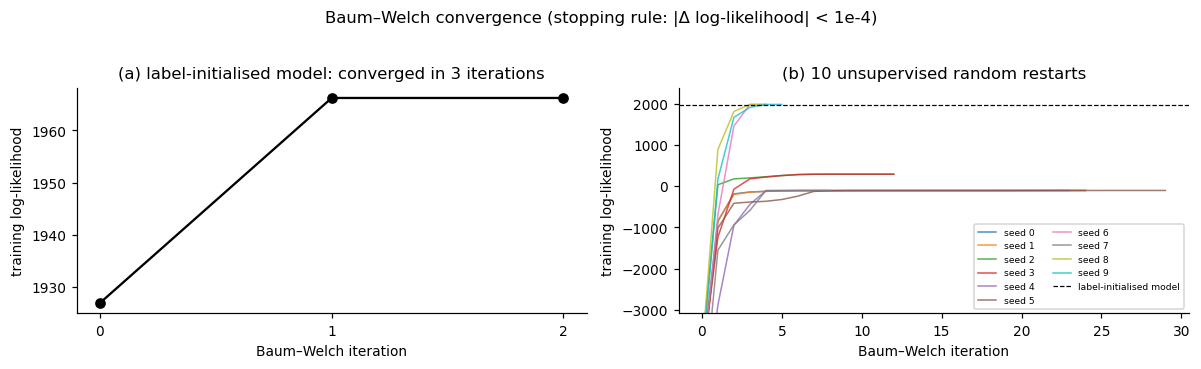

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(h.iteration, h.log_likelihood, 'o-', color='k')
axes[0].set_title(f'(a) label-initialised model: converged in {len(h)} iterations'); axes[0].set_xticks(h.iteration)
for r in restarts:
    hh = pd.DataFrame(r['model'].history)
    axes[1].plot(hh.iteration, hh.log_likelihood, lw=1, alpha=.8, label=f"seed {r['seed']}")
axes[1].axhline(hmm.history[-1]['log_likelihood'], ls='--', color='k', lw=.8, label='label-initialised model')
axes[1].set_title('(b) 10 unsupervised random restarts')
axes[1].set_ylim(bottom=min(pd.DataFrame(r['model'].history).log_likelihood.iloc[1] for r in restarts) - 200)
axes[1].legend(fontsize=6, ncol=2)
for ax in axes:
    ax.set_xlabel('Baum–Welch iteration'); ax.set_ylabel('training log-likelihood')
fig.suptitle('Baum–Welch convergence (stopping rule: |Δ log-likelihood| < 1e-4)', y=1.03)
plt.tight_layout(); savefig('fig04_convergence.png'); plt.show()

## 4. Learned parameters

Initial state distribution π: {'still': 0.25, 'standing': 0.25, 'walking': 0.25, 'jumping': 0.25}
Expected stay per state (s) = HOP / (1 − a_ii): {'still': 20.5, 'standing': 12.1, 'walking': 12.1, 'jumping': 19.4}


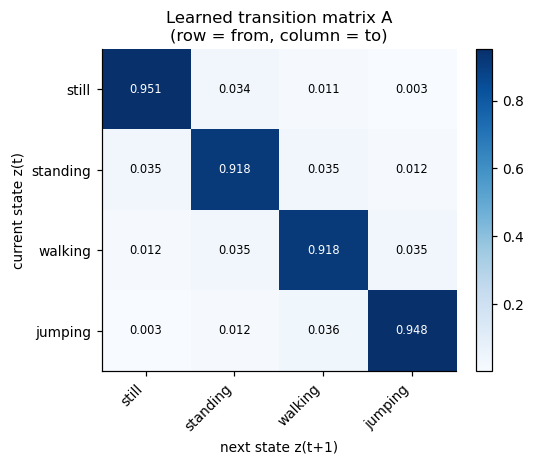

In [12]:
def heatmap(ax, M, row_labels, col_labels, title, fmt='{:.3f}', cmap='Blues', **kw):
    im = ax.imshow(M, cmap=cmap, aspect='auto', **kw)
    ax.set_xticks(range(len(col_labels))); ax.set_xticklabels(col_labels, rotation=45, ha='right')
    ax.set_yticks(range(len(row_labels))); ax.set_yticklabels(row_labels)
    vmax, vmin = np.nanmax(M), np.nanmin(M)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M[i, j]
            light = (v - vmin) / (vmax - vmin + 1e-12) > 0.6 if cmap != 'RdBu_r' else abs(v) > 0.6 * max(abs(vmin), abs(vmax))
            ax.text(j, i, fmt.format(v), ha='center', va='center', fontsize=7.5, color='white' if light else 'black')
    ax.set_title(title)
    return im

print('Initial state distribution π:', {a: round(float(p), 3) for a, p in zip(ACTIVITIES, hmm.pi)})
fig, ax = plt.subplots(figsize=(4.6, 3.8))
im = heatmap(ax, hmm.A, ACTIVITIES, ACTIVITIES, 'Learned transition matrix A\n(row = from, column = to)')
ax.set_xlabel('next state z(t+1)'); ax.set_ylabel('current state z(t)')
plt.colorbar(im, ax=ax, fraction=.046)
expected_dur = 1 / (1 - np.diag(hmm.A))
print('Expected stay per state (s) = HOP / (1 − a_ii):', {a: round(float(d), 1) for a, d in zip(ACTIVITIES, expected_dur * HOP_S)})
savefig('fig05_transition_matrix.png'); plt.show()

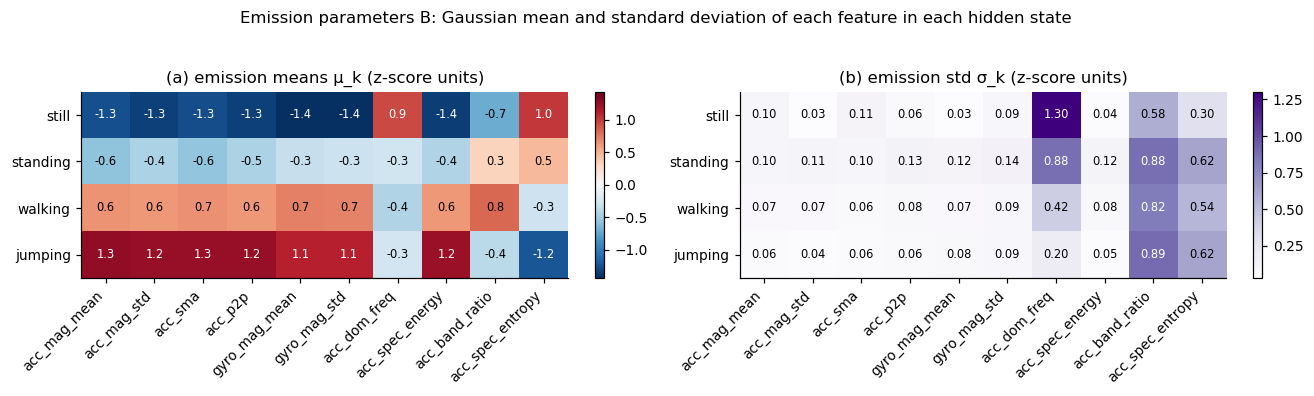

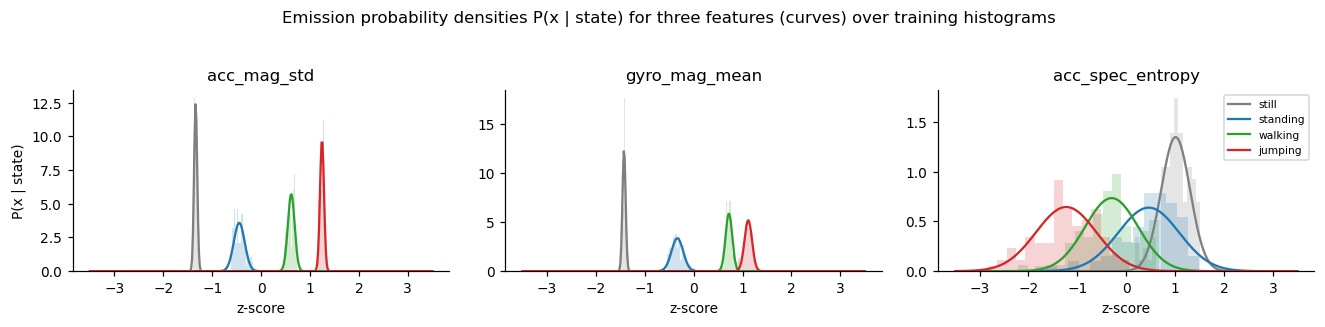

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={'width_ratios': [1, 1]})
im0 = heatmap(axes[0], hmm.means, ACTIVITIES, FEATURES, '(a) emission means μ_k (z-score units)',
              fmt='{:.1f}', cmap='RdBu_r', vmin=-np.abs(hmm.means).max(), vmax=np.abs(hmm.means).max())
plt.colorbar(im0, ax=axes[0], fraction=.03)
im1 = heatmap(axes[1], np.sqrt(hmm.vars), ACTIVITIES, FEATURES, '(b) emission std σ_k (z-score units)', fmt='{:.2f}', cmap='Purples')
plt.colorbar(im1, ax=axes[1], fraction=.03)
fig.suptitle('Emission parameters B: Gaussian mean and standard deviation of each feature in each hidden state', y=1.04)
plt.tight_layout(); savefig('fig06_emission_params.png'); plt.show()

# emission densities for three key features
show = ['acc_mag_std', 'gyro_mag_mean', 'acc_spec_entropy']
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8))
for ax, name in zip(axes, show):
    k = FEATURES.index(name); xs = np.linspace(-3.5, 3.5, 400)
    for s, act in enumerate(ACTIVITIES):
        mu, sd = hmm.means[s, k], np.sqrt(hmm.vars[s, k])
        ax.plot(xs, np.exp(-0.5 * ((xs - mu) / sd) ** 2) / (sd * np.sqrt(2 * np.pi)), color=COLORS[act], label=act)
        ax.hist(Z_train[feat_train.activity.values == act, k], bins=15, density=True, color=COLORS[act], alpha=.2)
    ax.set_title(name); ax.set_xlabel('z-score')
axes[0].set_ylabel('P(x | state)'); axes[2].legend(fontsize=7)
fig.suptitle('Emission probability densities P(x | state) for three features (curves) over training histograms', y=1.04)
plt.tight_layout(); savefig('fig07_emission_densities.png'); plt.show()

## 5. Evaluation helpers

Each window is one sample. For every activity *k*, with that activity treated as positive and the rest as negative:
* **Sensitivity** (recall) = TP / (TP + FN): the share of true *k* windows that are recognised.
* **Specificity** = TN / (TN + FP): the share of non-*k* windows that are correctly *not* labelled *k*.
* **Overall accuracy** = correct windows / all windows (one number for the whole set).

In [14]:
def confusion(y_true, y_pred, K=4):
    C = np.zeros((K, K), dtype=int)
    for t, p in zip(y_true, y_pred):
        C[t, p] += 1
    return C

def metrics_table(y_true, y_pred):
    C = confusion(y_true, y_pred); n = C.sum(); rows = []
    for k, act in enumerate(ACTIVITIES):
        tp = C[k, k]; fn = C[k].sum() - tp; fp = C[:, k].sum() - tp; tn = n - tp - fn - fp
        rows.append({'State (Activity)': act, 'Number of Samples': int(C[k].sum()),
                     'Sensitivity': tp / (tp + fn) if tp + fn else np.nan,
                     'Specificity': tn / (tn + fp) if tn + fp else np.nan})
    T = pd.DataFrame(rows); T['Overall Accuracy'] = np.trace(C) / n
    return T, C

def plot_confusion(C, title, fname):
    fig, ax = plt.subplots(figsize=(4.4, 3.8))
    im = heatmap(ax, C, ACTIVITIES, ACTIVITIES, title, fmt='{:.0f}', cmap='Greens')
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); plt.colorbar(im, ax=ax, fraction=.046)
    savefig(fname); plt.show()

## 6. Validation on held-out recording days (before the test files)

As an extra generalisation check, the whole pipeline (scaler + HMM) is retrained on one recording session and evaluated on the other:
* **Session A**: 23 Oct, files `_01`–`_04`
* **Session B**: 25–26 Oct, files `_05`–`_13`

These come from different days and places. To see Viterbi make real activity switches, the held-out recordings of each activity are also **joined end to end into one continuous signal** before windowing. Windows that straddle a join mix two activities, which mimics a real transition.

Cross-session validation (each held-out recording decoded as its own sequence):


,State (Activity),Number of Samples,Sensitivity,Specificity,Overall Accuracy
0,still,96,1.0,1.0,1.0
1,standing,91,1.0,1.0,1.0
2,walking,91,1.0,1.0,1.0
3,jumping,91,1.0,1.0,1.0


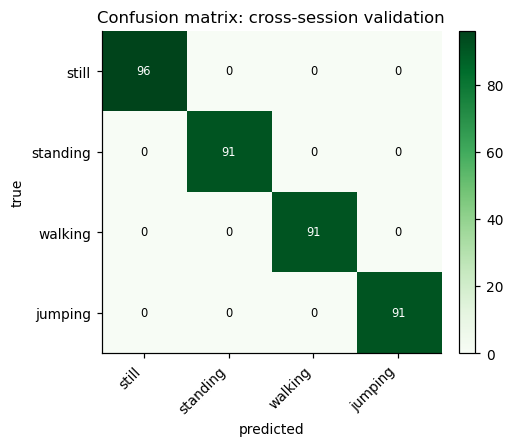

In [15]:
def fit_pipeline(feat_df):
    sc = FeatureScaler().fit(feat_df)
    Z = sc.transform(feat_df)
    seqs, labels, _ = to_sequences(feat_df.reset_index(drop=True), Z)
    model = GaussianHMM(4, tol=1e-4, trans_prior=TRANS_PRIOR).fit(seqs, *init_from_labels(seqs, labels))
    return sc, model

def window_labels(t_rec, segments):
    # Majority label for each window from (start, end, activity) segments; returns -1 if unlabelled.
    lab = np.full(len(t_rec), -1)
    for s, e, act in segments:
        lab[(t_rec >= s) & (t_rec < e)] = ACTIVITIES.index(act)
    vals = [np.bincount(lab[i:i + WIN][lab[i:i + WIN] >= 0], minlength=4) for i in range(0, len(lab) - WIN + 1, HOP)]
    return np.array([v.argmax() if v.sum() else -1 for v in vals])

def featurize_continuous(df):
    return pd.DataFrame([extract_features(w) for _, w in sliding_windows(df)])

cv_true, cv_pred, chained = [], [], {}
for train_s, test_s in [('B (25–26 Oct)', 'A (23 Oct)'), ('A (23 Oct)', 'B (25–26 Oct)')]:
    sc, model = fit_pipeline(feat_train[feat_train.session == train_s])
    held = feat_train[feat_train.session == test_s].reset_index(drop=True)
    seqs, labels, _ = to_sequences(held, sc.transform(held))
    for X, y in zip(seqs, labels):
        cv_true.append(y); cv_pred.append(model.viterbi(X)[0])
    # build one chained sequence from the first held-out file of each activity, in a realistic order
    order = ['still', 'standing', 'walking', 'jumping', 'walking', 'standing']
    used = {a: iter([r for r in train_recs if r['activity'] == a and
                     ((int(r['rec'][-2:]) <= 4) == test_s.startswith('A'))]) for a in ACTIVITIES}
    parts, segs, t0 = [], [], 0.0
    for a in order:
        d = next(used[a])['data'].copy(); dur = len(d) / FS
        d['t_rec'] = t0 + np.arange(len(d)) / FS; parts.append(d); segs.append((t0, t0 + dur, a)); t0 += dur
    chain = pd.concat(parts, ignore_index=True)
    Xc = sc.transform(featurize_continuous(chain)); yc = window_labels(chain['t_rec'].values, segs)
    chained[test_s] = (yc, model.viterbi(Xc)[0], model.posteriors(Xc))

T_cv, C_cv = metrics_table(np.concatenate(cv_true), np.concatenate(cv_pred))
print('Cross-session validation (each held-out recording decoded as its own sequence):')
display(T_cv.round(3))
plot_confusion(C_cv, 'Confusion matrix: cross-session validation', 'fig08_confusion_crosssession.png')

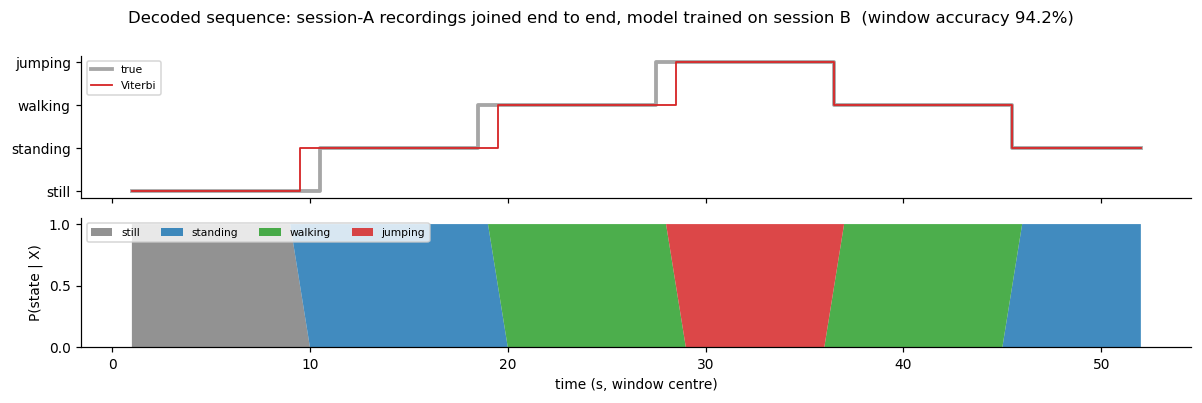

In [16]:
def plot_decoded(y_true, y_pred, post, title, fname):
    fig, axes = plt.subplots(2, 1, figsize=(11, 3.6), sharex=True, gridspec_kw={'height_ratios': [1.1, 1]})
    t = np.arange(len(y_pred)) * HOP_S + WIN_S / 2
    axes[0].step(t, y_true, where='mid', color='k', lw=2.5, alpha=.35, label='true')
    axes[0].step(t, y_pred, where='mid', color='#d62728', lw=1.2, label='Viterbi')
    axes[0].set_yticks(range(4)); axes[0].set_yticklabels(ACTIVITIES); axes[0].legend(loc='upper left', fontsize=7)
    axes[1].stackplot(t, post.T, colors=[COLORS[a] for a in ACTIVITIES], labels=ACTIVITIES, alpha=.85)
    axes[1].set_ylabel('P(state | X)'); axes[1].set_xlabel('time (s, window centre)')
    axes[1].legend(loc='upper left', fontsize=7, ncol=4)
    acc = (y_true == y_pred)[y_true >= 0].mean()
    fig.suptitle(f'{title}  (window accuracy {acc:.1%})', y=1.0)
    plt.tight_layout(); savefig(fname); plt.show()

yc, pc, post = chained['A (23 Oct)']
plot_decoded(yc, pc, post, 'Decoded sequence: session-A recordings joined end to end, model trained on session B',
             'fig09_decoded_chained_validation.png')

## 7. Evaluation on unseen test data

The two test recordings are stored as `data/test/test_01/` and `data/test/test_02/`. Each folder holds the Sensor Logger export (`Accelerometer.csv`, `Gyroscope.csv`) and a `labels.txt` file with one `start_s,end_s,activity` line per segment. Time is counted from the start of the recording. These files were **never used for training or for fitting the scaler**.

**How the unseen data were obtained.** Both files were recorded on 26 Oct 2026, in a new session and a new location not used for any training file. Each one follows a fixed script with about 12 s per activity, recorded without stopping:
* `test_01`: still → standing → walking → jumping (48 s)
* `test_02`: walking → standing → jumping → still (51 s)

The order of activities comes from the script. The switch times were marked by looking at the raw signal plots, where every change is a clear step in intensity. The short handling moments (picking the phone up from the table in `test_01`, 12.9–14.3 s, and putting it down in `test_02`, 38.2–39.0 s) belong to no activity, so they are left unlabelled and **excluded from scoring**. They are still part of the decoded sequence. The final model from Section 3 (trained on all 52 files) decodes each test recording as one continuous sequence.

In [17]:
def load_test_recording(folder):
    acc = pd.read_csv(os.path.join(folder, 'Accelerometer.csv')).sort_values('time')
    gyr = pd.read_csv(os.path.join(folder, 'Gyroscope.csv')).sort_values('time')
    acc = acc.rename(columns={'time': 'timestamp_ns', 'x': 'acc_x', 'y': 'acc_y', 'z': 'acc_z'})
    gyr = gyr.rename(columns={'time': 'timestamp_ns', 'x': 'gyro_x', 'y': 'gyro_y', 'z': 'gyro_z'}).drop(columns='seconds_elapsed')
    df = pd.merge_asof(acc, gyr, on='timestamp_ns', direction='nearest', tolerance=5_000_000).dropna()
    df = clean(resample_uniform(df), max_len=None)          # trim start/stop taps, keep full length
    segs = []
    with open(os.path.join(folder, 'labels.txt')) as fh:
        for line in fh:
            parts = [p.strip() for p in line.strip().split(',')]
            if len(parts) == 3 and parts[2] in ACTIVITIES:
                segs.append((float(parts[0]), float(parts[1]), parts[2]))
    return df, segs

test_dirs = sorted(d for d in glob.glob(os.path.join(DATA_DIR, 'test', 'test_*')) if os.path.isdir(d))
TEST_AVAILABLE = len(test_dirs) > 0
print('Test recordings found:', [os.path.basename(d) for d in test_dirs] if TEST_AVAILABLE
      else 'none yet: add data/test/test_01 and test_02, then re-run this section')

Test recordings found: ['test_01', 'test_02']


test_01: 45.9 s, 44 windows, accuracy 90.9%


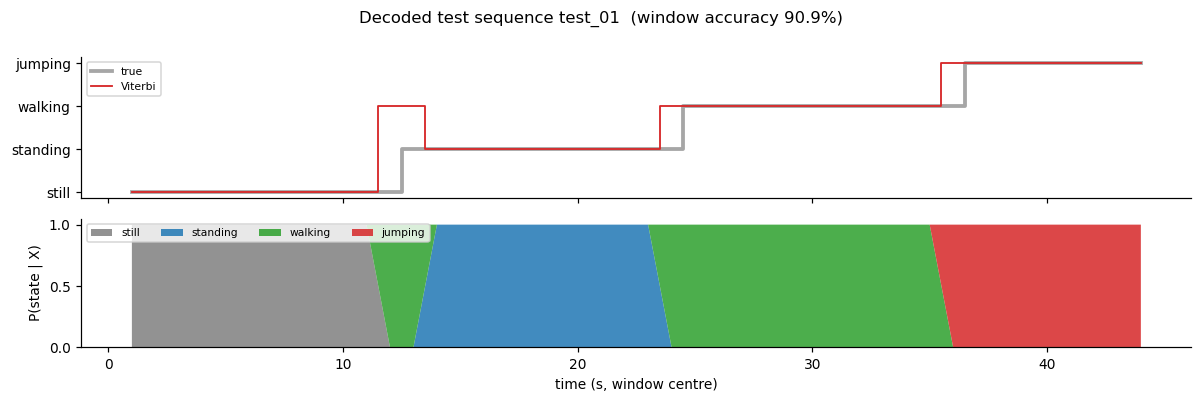

test_02: 48.9 s, 47 windows, accuracy 91.5%


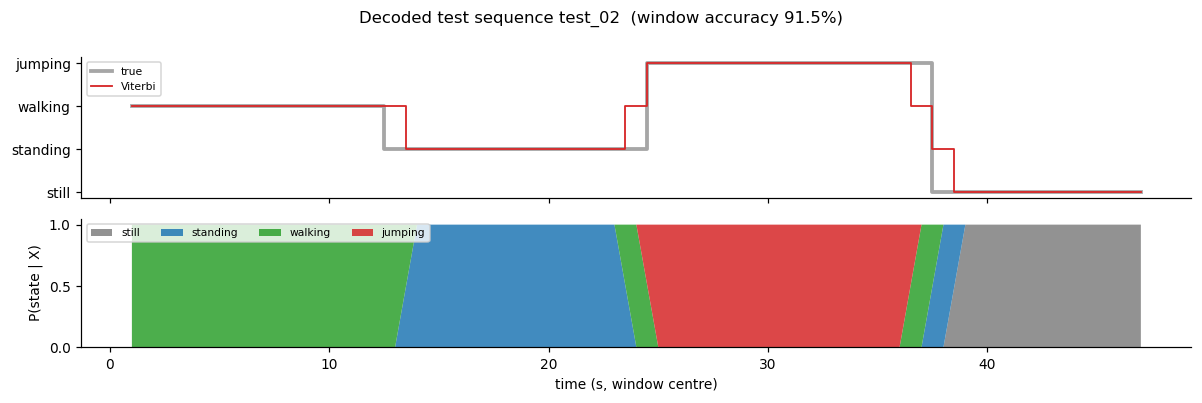

,State (Activity),Number of Samples,Sensitivity,Specificity,Overall Accuracy
0,still,22,0.909,1.000,0.912
1,standing,24,0.833,0.985,0.912
2,walking,24,0.958,0.910,0.912
3,jumping,21,0.952,0.986,0.912


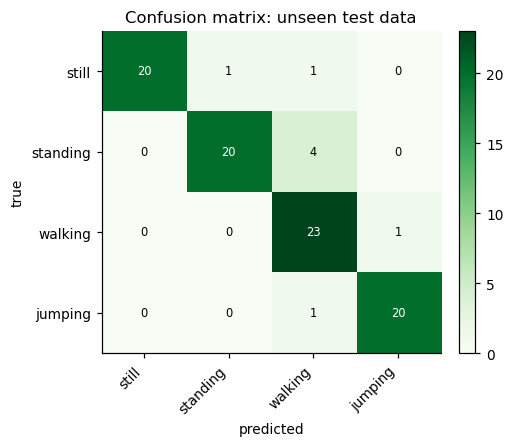

In [18]:
if TEST_AVAILABLE:
    test_true, test_pred = [], []
    for i, folder in enumerate(test_dirs, start=1):
        df, segs = load_test_recording(folder)
        X = scaler.transform(featurize_continuous(df))
        y = window_labels(df['t_rec'].values, segs)
        path, _ = hmm.viterbi(X)
        keep = y >= 0
        test_true.append(y[keep]); test_pred.append(path[keep])
        print(f"{os.path.basename(folder)}: {len(df) / FS:.1f} s, {len(X)} windows, accuracy {(y[keep] == path[keep]).mean():.1%}")
        plot_decoded(y, path, hmm.posteriors(X), f'Decoded test sequence {os.path.basename(folder)}',
                     f'fig{9 + i:02d}_decoded_{os.path.basename(folder)}.png')
    T_test, C_test = metrics_table(np.concatenate(test_true), np.concatenate(test_pred))
    display(T_test.round(3))
    T_test.round(3).to_csv(os.path.join(FIG_DIR, 'test_metrics_table.csv'), index=False)
    plot_confusion(C_test, 'Confusion matrix: unseen test data', 'fig12_confusion_test.png')

## 8. Summary of results

The table below collects the numbers the report needs. Re-run the notebook after adding the test files to fill in the test rows.

In [19]:
y_hat_train = np.concatenate([hmm.viterbi(X)[0] for X in train_seqs])
summary_rows = [{'evaluation': 'training (52 files, resubstitution)', 'windows': len(y_train),
                 'accuracy': (y_hat_train == y_train).mean()},
                {'evaluation': 'cross-session validation', 'windows': int(C_cv.sum()), 'accuracy': np.trace(C_cv) / C_cv.sum()}]
for s, (yc, pc, _) in chained.items():
    k = yc >= 0
    summary_rows.append({'evaluation': f'chained held-out sequence, session {s}', 'windows': int(k.sum()),
                         'accuracy': (yc[k] == pc[k]).mean()})
if TEST_AVAILABLE:
    summary_rows.append({'evaluation': 'UNSEEN TEST (2 files)', 'windows': int(C_test.sum()), 'accuracy': np.trace(C_test) / C_test.sum()})
pd.DataFrame(summary_rows).round(3)

,evaluation,windows,accuracy
0,"training (52 files, resubstitution)",369,1.000
1,cross-session validation,369,1.000
2,"chained held-out sequence, session A (23 Oct)",52,0.942
3,"chained held-out sequence, session B (25–26 Oct)",50,0.920
4,UNSEEN TEST (2 files),91,0.912
